# 跨所 TradFi 永续排查：1,000 个合约里有 43% 不是币

**问题**：mexc / gate 各挂着 1,000 多个永续合约，里面有没有币安 TradFi 那种「传统金融标的」的衍生品？以后怎么判断？

**结论先行**

| 判断 | 数字 |
|---|---|
| **有，而且是普遍现象** | 7 家合约所都有，htx **55.2%**、mexc **43.3%**、okx **35.0%** |
| 永续总量 | 5,620 个合约里 **1,690 个（30.1%）** 标的是股票/商品/指数 |
| 标的最多的是美股 | mexc 450、bitget 187、bybit 186、htx 181、gate 179 |
| 现货侧几乎干净 | 所有所现货 TradFi 占比 **≤1.0%** |
| 判断依据 | 交易所命名后缀 + 币安 `underlyingType`（权威字段）+ 撞车名单 |
| **最大的坑** | ticker 撞车：`DIA`/`SPX`/`ALL` 既是币又是传统标的，按名字判必错；已单独标出 **41 条 ambiguous** |

> 本文数字全部由 `scripts/collect_facts.py` 实测生成到 `data/facts.json`，正文由 build 脚本注入，代码 cell 逐值断言。


In [1]:

import json
from pathlib import Path

ROOT = Path("/mnt/hgfs/e/workspace/FutureTradeDev/pond")
OUTDIR = ROOT / "report" / "manual" / "tradfi_perp_survey"
facts = json.loads((OUTDIR / "data" / "facts.json").read_text(encoding="utf-8"))
B, O = facts["binance"], facts["ours"]

# ── 逐值断言：facts 变了这里先炸，避免正文与数据脱节 ──
assert B["total_symbols"] == 936, B["total_symbols"]
assert B["tradifi_underlyings"] == 232, B["tradifi_underlyings"]
assert B["contract_type"]["TRADIFI_PERPETUAL"] == 229
assert O["instrument_class_rows"] == 12658, O["instrument_class_rows"]

vt = {(r["venue"], r["market"]): r for r in O["by_venue_type"]}
assert len(vt) == 16, len(vt)
assert vt[("mexc", "perp")]["tradfi"] == 470
assert vt[("mexc", "perp")]["tradfi_pct"] == 43.3
assert vt[("htx", "perp")]["tradfi_pct"] == 55.2
assert vt[("gate", "perp")]["tradfi_pct"] == 20.4
assert vt[("upbit", "spot")]["tradfi"] == 0
assert vt[("upbit", "spot")]["total"] == 299
assert len(O["ambiguous"]) == 41, len(O["ambiguous"])

print(f"facts OK  generated_at={facts['generated_at']}")


facts OK  generated_at=2026-10-28T15:29:19+00:00


## 1. 币安是怎么标的：`underlyingType`

币安 2026 年上线的 TradFi 永续，在 `/fapi/v1/exchangeInfo` 里给了两个**显式字段**：

```
contractType   = PERPETUAL / TRADIFI_PERPETUAL / CURRENT_QUARTER / NEXT_QUARTER
underlyingType = COIN / EQUITY / HK_EQUITY / KR_EQUITY / CN_EQUITY /
                 COMMODITY / INDEX / PREMARKET / FX
```

这是**交易所自己给的分类**，比任何名字推断都可靠。问题只在于：其他所没有这个字段。
所以我们的做法是——把其他所的基准资产名对齐币安 `baseAsset`，撞车的单独标出来。


In [2]:

import pandas as pd

bn = pd.DataFrame(
    sorted(B["underlying_type"].items(), key=lambda kv: -kv[1]),
    columns=["underlyingType", "合约数"],
)
display(bn)
print("contractType:", B["contract_type"])
print("TradFi 标的（非 COIN）:", B["tradifi_underlyings"], "个 →", B["tradifi_breakdown"])


,underlyingType,合约数
0,COIN,703
1,EQUITY,191
2,HK_EQUITY,15
3,COMMODITY,8
4,KR_EQUITY,8
5,PREMARKET,5
6,INDEX,3
7,CN_EQUITY,2
8,FX,1


contractType: {'PERPETUAL': 703, 'TRADIFI_PERPETUAL': 229, 'CURRENT_QUARTER': 2, 'NEXT_QUARTER': 2}
TradFi 标的（非 COIN）: 232 个 → {'index': 3, 'commodity': 8, 'equity': 190, 'premarket': 5, 'kr_equity': 8, 'hk_equity': 15, 'cn_equity': 2, 'fx': 1}


## 2. 判定优先级：四层，越靠前越可信

| 层 | 依据 | 判了多少条 | 可靠性 |
|---|---|---|---|
| ① 交易所命名 | gate/mexc/bitget 给股票加 `STOCK` 后缀，pre-IPO 用 `pre` 前缀 | 452 | 高（交易所显式标记） |
| ② 币安 `underlyingType` | 基准资产名对齐币安 | 1,223 | 高（交易所权威字段） |
| ③ 无歧义别名 | `SPX500` / `NAS100` / `NDX100` / `US30` / `XAUT` 这类带后缀、不会和币撞车 | 36 | 中高 |
| ④ 撞车名单 | `DIA`/`SPX`/`ALL`/`META` 等既是币又是传统标的 → 标 `ambiguous`，不硬判 | 36 | 必须复核 |
| 默认 | 其余按加密 | 10,612 | — |
| 所级覆盖 | upbit 是纯加密现货所 | 299 | 高 |

**为什么不能只靠名字**：币安 `DIAUSDT` 的 `underlyingType` 是 **COIN**（DIA 预言机币），
不是道指 ETF `DIA`；`SPXUSDT` 是 SPX6900 meme 币，不是标普 500。
直接按 ticker 匹配，会把一堆 meme 币标成股票。


In [3]:

via = pd.DataFrame(
    sorted(O["matched_via"].items(), key=lambda kv: -kv[1]),
    columns=["判定依据", "条数"],
)
display(via)
print("ambiguous（撞车待判）:", len(O["ambiguous"]), "条")


,判定依据,条数
0,default,10612
1,binance,1223
2,venue_suffix,452
3,venue_crypto_only,299
4,heuristic,36
5,collision,36


ambiguous（撞车待判）: 41 条


## 3. 结论一：TradFi 占比按所排序

**永续是重灾区，现货是干净的。** htx 挂的合约里有超过一半是股票/商品/指数。

全局：永续 5,620 个里 TradFi **1,690 个（30.1%）**；
现货 9,492 个里 TradFi **36 个（0.38%）**。


In [4]:

rows = []
for r in O["by_venue_type"]:
    rows.append({
        "所": r["venue"], "类型": r["market"], "合约数": r["total"],
        "加密": r["crypto"],
        "股票类": r["equity"] + r["hk_equity"] + r["kr_equity"] + r["cn_equity"] + r["premarket"],
        "商品": r["commodity"], "指数": r["index"], "待判": r["ambiguous"],
        "TradFi": r["tradfi"], "TradFi%": r["tradfi_pct"],
    })
df = pd.DataFrame(rows).sort_values(["类型", "TradFi%"], ascending=[True, False])
display(df.reset_index(drop=True))

perp = df[df["类型"] == "perp"]
print(f"永续合计 {perp['合约数'].sum():,} 个，TradFi {perp['TradFi'].sum():,} 个 "
      f"= {perp['TradFi'].sum() / perp['合约数'].sum() * 100:.1f}%")
spot = df[df["类型"] == "spot"]
print(f"现货合计 {spot['合约数'].sum():,} 个，TradFi {spot['TradFi'].sum()} 个 "
      f"= {spot['TradFi'].sum() / spot['合约数'].sum() * 100:.2f}%")


,所,类型,合约数,加密,股票类,商品,指数,待判,TradFi,TradFi%
0,htx,perp,397,176,209,8,1,2,219,55.2
1,mexc,perp,1085,612,461,6,3,3,470,43.3
2,okx,perp,511,327,172,6,1,5,179,35.0
3,bybit,perp,813,595,206,6,0,6,212,26.1
4,bitget,perp,867,641,208,10,1,6,220,25.4
5,kucoin,perp,702,525,163,9,0,5,172,24.5
6,gate,perp,1066,843,205,8,3,6,217,20.4
7,hyperliquid,perp,179,177,0,1,0,1,1,0.6
8,kucoin,spot,815,805,5,2,1,2,8,1.0
9,htx,spot,580,575,3,1,0,1,4,0.7


永续合计 5,620 个，TradFi 1,690 个 = 30.1%
现货合计 9,492 个，TradFi 36 个 = 0.38%


saved tradfi_share_by_venue.png


/home/heavy/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


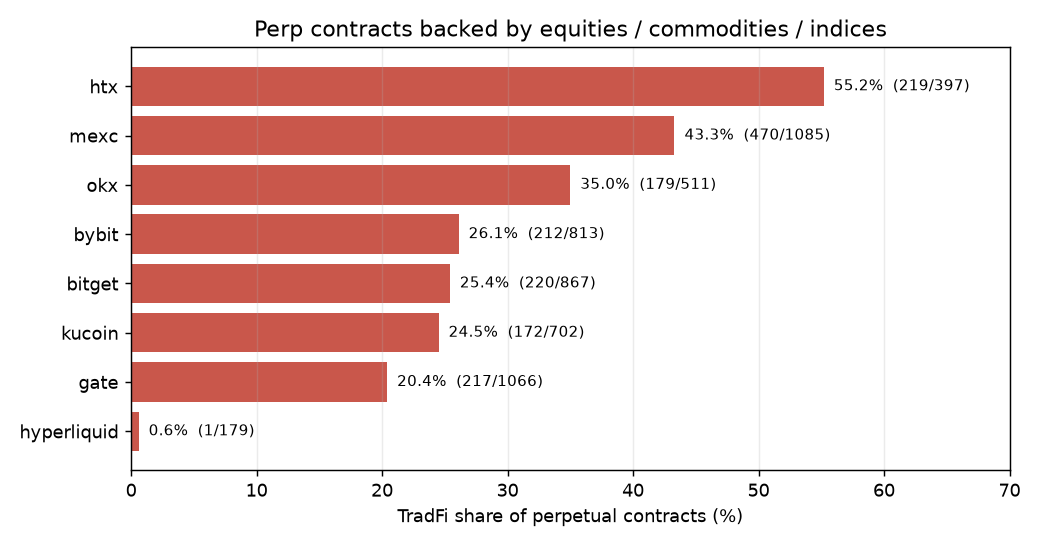

In [5]:

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

p = perp.sort_values("TradFi%")
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=130)
bars = ax.barh(p["所"], p["TradFi%"], color="#c0392b", alpha=0.85)
for b, (_, r) in zip(bars, p.iterrows()):
    ax.text(r["TradFi%"] + 0.8, b.get_y() + b.get_height() / 2,
            f"{r['TradFi%']:.1f}%  ({r['TradFi']}/{r['合约数']})",
            va="center", fontsize=8.5)
ax.set_xlabel("TradFi share of perpetual contracts (%)")
ax.set_title("Perp contracts backed by equities / commodities / indices")
ax.set_xlim(0, 70)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fp = OUTDIR / "tradfi_share_by_venue.png"
fig.savefig(fp)
print("saved", fp.name)
plt.close(fig)

from IPython.display import Image, display as _d
_d(Image(filename=str(fp)))


## 4. 结论二：按标的类别拆开看

美股是绝对主力（每家都在 140~460 个量级），港股/韩股集中在 htx、bybit、gate、bitget，
pre-IPO（OpenAI / Anthropic / Moonshot / Oura 这类未上市公司）每所也有 3~6 个。


In [6]:

cat = pd.DataFrame(O["perp_category"]).T.fillna(0).astype(int)   # 行=所, 列=类别
WANT = ["equity", "hk_equity", "kr_equity", "cn_equity", "premarket", "commodity", "index", "fx"]
cat = cat.reindex(columns=[c for c in WANT if c in cat.columns]).fillna(0).astype(int)
cat.columns = ["美股", "港股", "韩股", "A股", "pre-IPO", "商品", "指数", "外汇"][: len(cat.columns)]
cat["合计"] = cat.sum(axis=1)
display(cat.sort_values("合计", ascending=False))
assert cat.loc["mexc", "美股"] == O["perp_category"]["mexc"]["equity"]


,美股,港股,韩股,A股,pre-IPO,商品,指数,外汇,合计
mexc,450,5,2,1,3,6,3,0,470
bitget,187,8,7,2,4,10,1,1,220
htx,181,14,8,2,4,8,1,1,219
gate,179,11,8,2,5,8,3,1,217
bybit,186,10,8,2,0,6,0,0,212
okx,154,6,6,2,4,6,1,0,179
kucoin,142,11,5,0,5,9,0,0,172
hyperliquid,0,0,0,0,0,1,0,0,1


## 5. 案例：ticker 撞车 —— 名字一样，东西完全不是一回事

| ticker | 币安 `underlyingType` | 币圈的另一种含义 |
|---|---|---|
| `DIA` | **COIN** | DIA 预言机币；`DIA` 同时是道指 ETF 的代码 |
| `SPX` | **COIN** | SPX6900 meme 币；`SPX` 也是标普 500 的口语代码 |
| `ALL` | **INDEX** | 币安把 ALL 标成 INDEX；`ALL` 也是 Allstate 保险的代码 |
| `META` | EQUITY | Meta Platforms；但 **upbit 的 META-KRW 是 Metadium（韩国币）** |

最后一行是真实踩到的坑：第一版按名字对齐币安，把 upbit 的 `META-KRW` 标成了美股，
而 upbit 根本没有股票——它是 Metadium。修法是给 upbit 加所级覆盖（纯加密所）。


In [7]:

cc = pd.DataFrame(
    [{"ticker": k, "币安 symbol": v.get("symbol"), "币安 underlyingType": v.get("underlying_type")}
     for k, v in B["collision_cases"].items()]
)
display(cc)

amb = pd.DataFrame(O["ambiguous"])
print(f"撞车待判 {len(amb)} 条，分布：")
display(amb.groupby(["venue", "underlying"]).size().reset_index(name="条数"))


,ticker,币安 symbol,币安 underlyingType
0,DIA,DIAUSDT,coin
1,SPX,SPXUSDT,coin
2,ALL,ALLUSDT,index
3,META,METAUSDT,equity


撞车待判 41 条，分布：


,venue,underlying,条数
0,bitget,COIN,1
1,bitget,DIA,1
2,bitget,MARA,1
3,bitget,META,1
4,bitget,MSTR,1
5,bitget,SPX,1
6,bybit,COIN,1
7,bybit,DIA,1
8,bybit,MARA,1
9,bybit,META,1


## 6. 同一个标的，几家在挂

以 AAPL / NVDA / XAU / OPENAI 为例看跨所覆盖面。这也解释了为什么这些标的
**不能进加密横截面因子池**——它们是同一个基本面暴露，跨所高度同质。


In [8]:

cv = pd.DataFrame(
    [{"标的": k, "在挂的所数": len(v), "所": ", ".join(sorted(v))}
     for k, v in O["cross_venue"].items()]
).sort_values("在挂的所数", ascending=False)
display(cv)


,标的,在挂的所数,所
3,XAU,8,"bitget, bybit, gate, htx, hyperliquid, kucoin,..."
0,AAPL,7,"bitget, bybit, gate, htx, kucoin, mexc, okx"
1,NVDA,6,"bitget, bybit, gate, htx, kucoin, okx"
5,OPENAI,6,"bitget, gate, htx, kucoin, mexc, okx"
2,TSLA,5,"bitget, bybit, gate, kucoin, okx"
4,SPX500,0,


## 7. 对研究的影响：做加密横截面必须先过滤

这些标的有三个特征，会**直接毁掉加密因子的 IC**：

1. **周末不交易**：美股永续周末价格冻结、成交趋零；加密永续周末成交约占 28%
2. **日内 17 小时休市**：16:00 ET 收盘到次日 09:30 ET 开盘，价格基本不动
3. **和 BTC 相关性接近 0**：跟的是美股 beta，不是加密 beta

混进横截面池的后果：因子"周末失效/周末有效"都是假的；排序里 30%
的样本根本不是同一个资产类别。过滤后规模：**3,896 / 5,620**。

```sql
-- 只要加密
SELECT venue, code FROM cryptos.instrument_class FINAL
WHERE asset_class = 'crypto' AND matched_via != 'collision';

-- 反过来：只取传统金融做另一个研究
SELECT venue, code, asset_class, underlying FROM cryptos.instrument_class FINAL
WHERE asset_class NOT IN ('crypto', 'ambiguous');
```


In [9]:

tot_perp = sum(r["total"] for r in O["by_venue_type"] if r["market"] == "perp")
tot_crypto = sum(r["crypto"] for r in O["by_venue_type"] if r["market"] == "perp")
print(f"过滤后可用于加密横截面的永续：{tot_crypto:,} / {tot_perp:,} 个")
assert tot_perp == 5620, tot_perp
assert tot_crypto == 3896, tot_crypto
assert tot_perp - tot_crypto == 1724


过滤后可用于加密横截面的永续：3,896 / 5,620 个


## 8. 局限与下一步

**当前判据的弱点**：命名法在「同一 ticker 两种含义」上必然失效，41 条 `ambiguous` 就是证据。

**更硬的判据：成交量指纹**（不看名字，只看行为）
- 美股永续：每天约 **17 小时零成交**（收盘到开盘）+ 周末全天空，合计约 65%~70% 小时零成交
- 加密永续：零成交小时 ≈ 0%

**为什么现在还不能用**：全量采集 2026-10-28 才开，`AAPL-USDT` 目前只有 20 根 1h bar，
样本不够。攒够 **2 周**（≈336 根）就能自动化：
1. 每所每个合约算「近 14 天零成交小时占比」
2. 占比 > 50% → 判 TradFi，覆盖命名法结果
3. 两种判据的一致率作为质检指标

**已知未覆盖**
- binance 未采集（`enabled: false`），但它有 **229 个 TRADIFI_PERPETUAL**，是数量最多的一家
- 现货侧的股票代币（gate 4 个、mexc 7 个、kucoin 5 个）未逐一核实


In [10]:

print("币安 TradFi 合约（未采集）：", B["contract_type"]["TRADIFI_PERPETUAL"], "个")
print("ambiguous 待成交量指纹复核：", len(O["ambiguous"]), "条")
print("\n复现：")
print("  /usr/bin/python3.12 scripts/classify_tradfi.py --write")
print("  /usr/bin/python3.12 report/manual/tradfi_perp_survey/scripts/collect_facts.py")
print("  /usr/bin/python3.12 report/manual/tradfi_perp_survey/scripts/tools/build_notebook.py")
print("  /usr/bin/python3.12 report/manual/tradfi_perp_survey/scripts/tools/exec_notebook.py")


币安 TradFi 合约（未采集）： 229 个
ambiguous 待成交量指纹复核： 41 条

复现：
  /usr/bin/python3.12 scripts/classify_tradfi.py --write
  /usr/bin/python3.12 report/manual/tradfi_perp_survey/scripts/collect_facts.py
  /usr/bin/python3.12 report/manual/tradfi_perp_survey/scripts/tools/build_notebook.py
  /usr/bin/python3.12 report/manual/tradfi_perp_survey/scripts/tools/exec_notebook.py
